# Game HUD perception

## What you will build

**Recipe 80 · Level 4 (Advanced) · `Box` + `Choice` + image.** Build a screenshot perception
pipeline that locates an energy meter, a card, an action button, or an enemy indicator and records
an intent in an in-memory `ActionLog`. Every entry has `executed=False`; no game is connected.

These are **Slay the Spire 2-inspired mock HUDs**, made from original rectangles, circles, and
invented card art. They are not actual Slay the Spire 2 screenshots or extracted game assets, and
this recipe does not establish support for that game. In the committed synthetic run, the fixtures and answers are authored for this recipe:
all numbers check this pipeline, not a model's performance.

A [typed question](../../docs/glossary.md#question) asks for a constrained answer: here a
fixed-choice UI judgment or one rectangle. `Box` always returns a rectangle even if its target
is absent, so a separate presence judgment must precede localization. Image inputs and `Box`
remain experimental. See [S02: Primitives](https://docs.typesafe.ai/primitives),
[S09: Images](https://docs.typesafe.ai/images), and
[S10: Box](https://docs.typesafe.ai/primitives/box).


Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S10: [Box](https://docs.typesafe.ai/primitives/box)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)


## Setup and run mode

The default [replay backend](../../docs/offline-and-live.md#the-two-modes) retrieves stored answers with no network or
API key. [Provenance](../../docs/glossary.md#provenance) records where each answer came from;
`synthetic` means this recipe authored it. Run this notebook from its own directory. Helpers
load by path so another recipe's `helpers.py` cannot be imported accidentally.

`get_backend` uses the same questions in live mode, with `images=True` and an explicit
`jev-1.14.0` pin for Box. Live opt-in, the global attempt budget, and recording are described in
[the README](README.md) and [live.md](../../docs/live.md). The executor always runs offline.
There are 20 scored captures plus one unscored demonstration.


In [1]:
from IPython.display import display
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import confusion_matrix
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import apply_style, plot_confusion_matrix, run_header, show_answer
from jev_cookbook.vision import draw_boxes, normalized_to_pixels, run_record

helpers = load_helpers()
examples, labels = load_inputs(), load_labels()
scored = [example for example in examples if example.split != "demo"]
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
run_header(80, "Game HUD perception", backend=backend, n_examples=len(scored))
check = " (a pipeline check, not a Jev result)" if backend.mode == "synthetic" else ""
selection = " (a selection step, not a reported result)"
apply_style()

Recipe 80: Game HUD perception
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 20 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Each input contains a local PNG path and the requested target name. Python reads the original
640 × 400 bytes and builds a content-addressed reference; only the image and the target
description enter the request. Filenames, capture IDs, split names, layout tags, and annotations
are not model state. The fixed-layout baseline receives the same pixels and target.

The PNGs live in `assets/`, beside the strict JSON-only `fixtures/` directory. A
[replay key](../../docs/glossary.md#replay-key) hashes the complete request, including the image
assets; changing image bytes or a question requires regenerating keys. An absent or malformed
fixture raises an error. See [vision helpers](../../docs/vision.md) and
[fixture layout](../../docs/fixtures.md).


In [2]:
demo = select_split(examples, "demo")[0]
state, assets, size = helpers.prepare(demo.fields)
print(
    {
        "state_fields": list(state),
        "target": state["requested_target"],
        "image_size": size,
        "asset_count": len(assets),
        "image_format": "png",
    }
)

{'state_fields': ['screenshot', 'requested_target'], 'target': "the ENERGY panel showing the player's energy, not the decoration", 'image_size': (640, 400), 'asset_count': 1, 'image_format': 'png'}


## The questions

Three independent `Choice` questions share the first request: current UI phase, whether the
requested target is fully identifiable, and whether a requested control is enabled. The options
include `ambiguous`, `absent`, `uncertain`, and `not_applicable`; presence is not inferred from
having received a rectangle.

Only a reported combat phase, a visible target, and a compatible enabled state permit a second
request. `Box` then asks for the target's tight outer rectangle. For an energy meter, an independent
`Choice` in that same request reads a displayed value from `0`, `1`, `2`, `3`, or `unreadable`.
It never estimates energy by arithmetic. Python converts an accepted numeral to an integer.

[Confidence](../../docs/glossary.md#confidence) is the typed answer's certainty measure, not a
proof of correctness. Choice confidence follows [S03](https://docs.typesafe.ai/confidence);
Box confidence is a separate reported field and may be missing. Reusing one cutoff here is an
explicit recipe policy chosen on validation data, not a claim that the two measures are calibrated.


In [3]:
for name, question in helpers.build_questions().items():
    print(name, question.to_dict())
for name, question in helpers.localization_questions("energy_meter").items():
    print(name, question.to_dict())

phase {'type': 'choice', 'instructions': 'Identify the currently visible UI phase.', 'criteria': {'combat': 'A combat board is active, without a menu or reward overlay.', 'menu': 'The pause or main menu is open, even if a combat board is visible behind it.', 'reward': 'A victory/reward screen is open, even if combat controls remain visible.', 'ambiguous': 'The visible screen does not establish one of these phases clearly.'}}
presence {'type': 'choice', 'instructions': 'Determine whether requested_target can be localized.', 'criteria': {'visible': 'The requested target is identifiable with all four outer edges visible.', 'absent': 'The requested target is absent from this screenshot.', 'uncertain': 'Occlusion, overlapping look-alikes, or unclear content prevents localization.'}}
enabled {'type': 'choice', 'instructions': 'Classify the visible enabled state of requested_target.', 'criteria': {'enabled': 'The requested card or action button is visibly enabled.', 'disabled': 'The requested

## One answer up close

This unscored demonstration uses the lowest candidate cutoff, 0.55. It shows the actual typed
answers before any aggregate, followed by the returned rectangle on the reflowed energy panel.
The demo does not select the final policy.


In [4]:
demo_observation = helpers.perceive(demo, backend, helpers.Policy(0.55))
for result in demo_observation.results:
    for name, answer in result.answers.items():
        print(name)
        show_answer(answer)
print("Final disposition:", demo_observation.event, "-", demo_observation.reason)

phase
Choice: combat (confidence 0.96)
  combat     0.97  ###################
  menu       0.01  
  reward     0.01  
  ambiguous  0.01  
Provenance: synthetic
presence
Choice: visible (confidence 0.95)
  visible    0.97  ###################
  absent     0.02  
  uncertain  0.02  
Provenance: synthetic
enabled
Choice: not_applicable (confidence 0.96)
  not_applicable  0.97  ###################
  enabled         0.01  
  disabled        0.01  
  uncertain       0.01  
Provenance: synthetic
target_box
Box: normalized coordinates (confidence 0.96)
  top=0.23, bottom=0.42, left=0.80, right=0.94
Provenance: synthetic
energy
Choice: 1 (confidence 0.96)
  1           0.97  ###################
  0           0.01  
  2           0.01  
  3           0.01  
  unreadable  0.01  
Provenance: synthetic
Final disposition: observe_energy - simulated intent only


Normalized edges: {'top': 0.225, 'bottom': 0.425, 'left': 0.796875, 'right': 0.9375}
Enclosing pixel bounds: (510, 90, 600, 170)


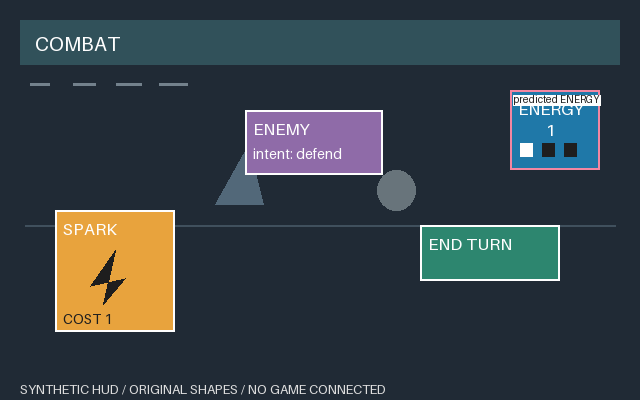

In [5]:
box = demo_observation.box
with Image.open(demo.fields["image"]) as image:
    if box is None:
        print("No approved box:", demo_observation.event, "-", demo_observation.reason)
        display(image.copy())
    else:
        print("Normalized edges:", dict(box))
        print("Enclosing pixel bounds:", normalized_to_pixels(box, *size))
        display(draw_boxes(image, {"predicted ENERGY": box}))

## Python's part

The [confidence gate](../../docs/glossary.md#confidence-gate) is a Python rule that requires a
reported confidence to meet a chosen cutoff. Here phase, presence, enabled state, Box, and the
energy answer when applicable all pass their own checks. `menu`, `reward`, `absent`, and
`disabled` produce `no_action` only after their confidence checks. `ambiguous`, `uncertain`,
missing Box confidence, invalid geometry, unreadable energy, or budget exhaustion produce
[review](../../docs/glossary.md#review): a deferred decision stored in a `ReviewQueue`.

Python validates finite normalized edges in `[0, 1]`, positive area, and a minimum width/height
of 12 pixels. It refuses invalid boxes instead of clipping them. Pixel starts round down and
ends round up; right/bottom edges are exclusive. The logged center is calculated in Python.
These are full-image coordinates: a resized, padded, or cropped screenshot would need an explicit
coordinate transform before any later use.

A capture gets at most two decision calls, checked before `backend.decide`. The live backend
separately limits network attempts, including retries. Validation memoizes identical requests
so policy comparisons do not resend them. Backend errors propagate; they never become fabricated
answers. The only effect below is a simulated log entry, never input to a real game.


In [6]:
print("Simulated action log:")
for entry in demo_observation.actions:
    print({key: entry[key] for key in ("kind", "payload", "executed")})
print("Review queue:", demo_observation.reviews)

Simulated action log:
{'kind': 'observe_energy', 'payload': {'id': 'd01', 'target': 'energy_meter', 'box': {'top': 0.225, 'bottom': 0.425, 'left': 0.796875, 'right': 0.9375}, 'center_pixel': [554, 129], 'energy': 1}, 'executed': False}
Review queue: []


## Evaluation

A [gold label](../../docs/glossary.md#gold-label) is the independently authored expected answer.
Each scored capture has separate phase, presence, enabled-state, energy, rectangle, and event
annotations, kept outside request state. Occluded targets are labeled `uncertain` with no
localizable rectangle; an absent target is labeled `absent`, not a zero-area box.

[Accuracy](../../docs/glossary.md#accuracy) is the fraction of correct answers. Phase and presence
accuracy use every capture. End-to-end event accuracy also uses every capture: a simulated intent
must match its event name, have intersection-over-union (IoU) at least 0.5 with the gold rectangle,
and match the energy value when applicable. IoU is intersection area divided by union area.
A correct `no_action` or expected `review` is scored as such; an unnecessary review misses the
expected event.

[Coverage](../../docs/glossary.md#coverage) is the fraction resolved without review; abstention is
one minus coverage. Resolved accuracy comes from `evaluate_outcomes` using the rule's actual
decisions, including non-confidence deferrals. Raw-box mean IoU covers only returned rectangles
with localizable gold targets, even if a later gate rejects them. Required-target mean IoU uses
all gold events that require localization and assigns zero to a missing accepted box. Both
print their denominator, so selective localization cannot conceal misses. False localizations
on absent targets and wrong simulated intents are counted separately.

### Select on validation and freeze

Compare cutoffs 0.55, 0.75, and 0.90 on eight validation captures. The frozen objective is lowest
resolved error, then greatest coverage, then the lowest cutoff, subject to coverage at least 0.5.
The tests pin that objective in source. Prompt wording, the 12-pixel bound, IoU criterion, and
the fixed-layout baseline are frozen before opening test. These synthetic selection numbers do
not establish a suitable cutoff for real screenshots.


In [7]:
validation = select_split(examples, "validation")
policy, selection_rows, validation_results = helpers.select_policy(
    validation, labels, backend, min_coverage=0.5
)
for row in selection_rows:
    print(f"Validation {helpers.printable(row)}{selection}{check}")
print(f"Frozen policy: {policy}{selection}{check}")
print(
    f"Validation unique decision calls: {len(validation_results)}, N={len(validation)}"
    f"{selection}{check}"
)

Validation {'threshold': 0.55, 'N': 8, 'phase_accuracy': 1.0, 'presence_accuracy': 1.0, 'event_accuracy': 0.875, 'abstention': 0.125, 'resolved_accuracy': 0.8571, 'raw_box_pairs': 4, 'raw_box_mean_iou': 0.8072, 'required_targets': 4, 'required_target_mean_iou': 0.8072, 'false_localizations_on_absent': 0, 'requests': 12, 'simulated_intents': 4, 'wrong_simulated_intents': 1} (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation {'threshold': 0.75, 'N': 8, 'phase_accuracy': 1.0, 'presence_accuracy': 1.0, 'event_accuracy': 0.875, 'abstention': 0.25, 'resolved_accuracy': 1.0, 'raw_box_pairs': 4, 'raw_box_mean_iou': 0.8072, 'required_targets': 4, 'required_target_mean_iou': 0.75, 'false_localizations_on_absent': 0, 'requests': 12, 'simulated_intents': 3, 'wrong_simulated_intents': 0} (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation {'threshold': 0.9, 'N': 8, 'phase_accuracy': 1.0, 'presence_accuracy': 1.0, 'event_ac

### Compare with a fixed-layout image baseline

The Python baseline samples the screenshot's phase-header colors and target-color occupancy
within fixed crop rectangles. Grey controls are disabled; three known energy-pip slots yield
an exact count for this mock UI. It has no access to labels, generator configuration, or layout
names. Both methods see the same 12 test captures. The baseline's pixel thresholds and anchors
come from the authored interface design and remain frozen; it has zero model calls.

A reflow can move a valid target outside its fixed crop. That is a genuine limit of this narrow
baseline, while the replayed semantic answers are still authored examples, not evidence that a
model improves on it. We now evaluate the held-out test split once. Subsequent charts and failure
inspection reuse those observations without another inference pass.


In [8]:
test = select_split(examples, "test")
test_observations = [helpers.perceive(example, backend, policy) for example in test]
baseline_observations = [helpers.fixed_layout(example) for example in test]
test_metrics = helpers.summarize(test_observations, labels)
baseline_metrics = helpers.summarize(baseline_observations, labels)
print(f"Test perception {helpers.printable(test_metrics)}{check}")
print(f"Test fixed-layout baseline {helpers.printable(baseline_metrics)}{check}")

Test perception {'N': 12, 'phase_accuracy': 0.9167, 'presence_accuracy': 1.0, 'event_accuracy': 0.75, 'abstention': 0.25, 'resolved_accuracy': 0.7778, 'raw_box_pairs': 7, 'raw_box_mean_iou': 0.8837, 'required_targets': 6, 'required_target_mean_iou': 0.6976, 'false_localizations_on_absent': 0, 'requests': 19, 'simulated_intents': 6, 'wrong_simulated_intents': 2} (a pipeline check, not a Jev result)
Test fixed-layout baseline {'N': 12, 'phase_accuracy': 1.0, 'presence_accuracy': 0.6667, 'event_accuracy': 0.75, 'abstention': 0.0833, 'resolved_accuracy': 0.7273, 'raw_box_pairs': 4, 'raw_box_mean_iou': 1.0, 'required_targets': 6, 'required_target_mean_iou': 0.6667, 'false_localizations_on_absent': 0, 'requests': 0, 'simulated_intents': 4, 'wrong_simulated_intents': 0} (a pipeline check, not a Jev result)


Test phase matrix, N=12, labels=['combat', 'menu', 'reward', 'ambiguous'], gold rows / predicted columns=[[9, 0, 0, 0], [0, 0, 0, 0], [1, 0, 1, 0], [0, 0, 0, 1]] (a pipeline check, not a Jev result)


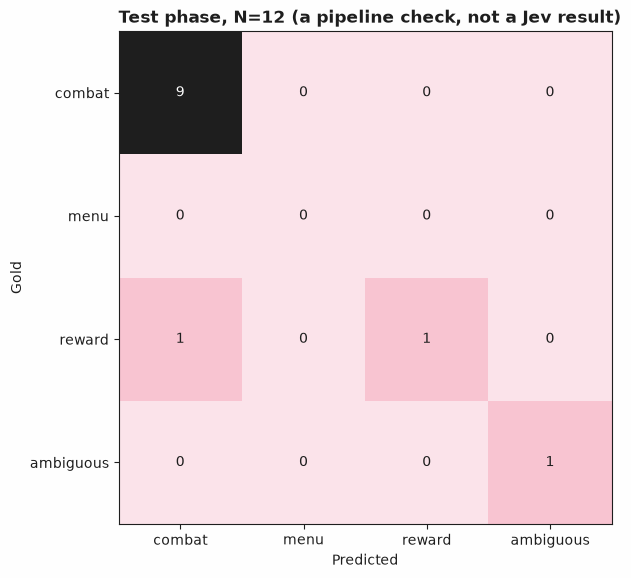

In [9]:
phase_matrix = confusion_matrix(
    [labels[obs.ident]["phase"] for obs in test_observations],
    [obs.phase for obs in test_observations],
    labels=list(helpers.PHASES),
)
print(
    f"Test phase matrix, N={len(test)}, labels={list(phase_matrix.labels)}, "
    f"gold rows / predicted columns={phase_matrix.matrix.tolist()}{check}"
)
plot_confusion_matrix(phase_matrix, title=f"Test phase, N={len(test)}{check}")

### Inspect the mistakes that survived

The frozen policy cannot turn a wrong confident judgment into a true one. The synthetic cases
include a rectangle around an overlapping distractor and a reward screen confidently labeled
as combat. Both can generate a wrong simulated intent. The printed failures below also include
deferrals when the gold event required localization. These demonstrate why the action boundary
remains a simulation and why phase accuracy alone does not establish end-to-end correctness.


In [10]:
for obs in test_observations:
    if not helpers.event_correct(obs, labels[obs.ident]):
        print(
            f"Test failure id={obs.ident}, predicted={obs.event}, "
            f"expected={labels[obs.ident]['event']}, reason={obs.reason}, "
            f"decision_calls={obs.requests}{check}"
        )
print(f"Test review entries, N={len(test)}{check}")
for obs in test_observations:
    for entry in obs.reviews:
        print({"id": obs.ident, "reason": entry["reason"], "status": entry["status"]})

Test failure id=t04, predicted=inspect_enemy, expected=inspect_enemy, reason=simulated intent only, decision_calls=2 (a pipeline check, not a Jev result)
Test failure id=t10, predicted=review, expected=observe_energy, reason=box confidence missing, decision_calls=2 (a pipeline check, not a Jev result)
Test failure id=t11, predicted=end_turn, expected=no_action, reason=simulated intent only, decision_calls=2 (a pipeline check, not a Jev result)
Test review entries, N=12 (a pipeline check, not a Jev result)
{'id': 't06', 'reason': 'ambiguous phase or target', 'status': 'pending'}
{'id': 't09', 'reason': 'ambiguous phase or target', 'status': 'pending'}
{'id': 't10', 'reason': 'box confidence missing', 'status': 'pending'}


## What was and was not measured

The following cell prints mode and N in every run, plus the returned model and capture date
when responses were recorded. Accounting records preserve unavailable values as `None`;
replay wall-clock time is never called inference latency. Synthetic responses have no actual
model, tokens, latency, or cost. The committed run is **not measured live**, and no actual game
screenshot was evaluated.

A live run is exploratory until its responses are deliberately recorded. Only recorded,
held-out measurements with the returned version, capture date, and N can be reported as results
for those captures. They would still make no claim about other screenshots or general game
support. [Offline and live](../../docs/offline-and-live.md) explains that boundary.


In [11]:
all_results = (
    demo_observation.results
    + validation_results
    + [result for obs in test_observations for result in obs.results]
)
accounting = [run_record(result, mode=backend.mode) for result in all_results]
print(f"Mode={backend.mode}")
if backend.mode == "synthetic":
    print("Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(validation)} validation, {len(test)} test; unscored demo=1{check}")
    print(
        "Not measured live; actual model=None, capture_date=None, input_tokens=None, "
        "output_tokens=None, latency_seconds=None, cost_usd=None."
    )
else:
    print(f"N: {len(validation)} validation, {len(test)} test; unscored demo=1")
    returned_models = sorted({result.model for result in all_results})
    capture_dates = sorted(
        {
            answer.provenance.date
            for result in all_results
            for answer in result.answers.values()
            if answer.provenance.date
        }
    )
    print("Returned models:", returned_models, "; response dates:", capture_dates)
    print("Live output is exploratory until recorded; inference latency/cost were not measured.")
print(f"Unique decision calls including demo: {len(all_results)}{check}")
print("First accounting row:", accounting[0])
if backend.mode == "live":
    print("Actual transport attempt count:", backend.ledger()["requests_made"])

Mode=synthetic
Not measured live: a pipeline check, not a Jev result.
N: 8 validation, 12 test; unscored demo=1 (a pipeline check, not a Jev result)
Not measured live; actual model=None, capture_date=None, input_tokens=None, output_tokens=None, latency_seconds=None, cost_usd=None.
Unique decision calls including demo: 33 (a pipeline check, not a Jev result)
First accounting row: {'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'}


## Next steps

Replace these mock HUDs with permissioned screenshots after removing private overlays. Keep
images upright and within [the documented limits](../../docs/vision.md), author fresh target and
phase labels independently, and split by capture session/layout to avoid repeated-image leakage.
Update target descriptions and the bounded energy vocabulary on validation only. Unknown values
should remain `unreadable`; never ask the model to invent arithmetic. Regenerate image references
and replay keys after any image or question edit, freeze the policy, and record new held-out calls
before making a model-quality claim. Keep simulated intents disconnected from game control.

Continue with [Card-game action selection](../36-card-game-action-selection/) for exact legal
choices from structured state, or [Abstention and review queues](../38-abstention-and-review-queues/)
for handling deferred decisions. Both are already published.

Sources: [S02: Primitives](https://docs.typesafe.ai/primitives),
[S03: Confidence](https://docs.typesafe.ai/confidence),
[S09: Images](https://docs.typesafe.ai/images),
[S10: Box](https://docs.typesafe.ai/primitives/box),
[S11: Models](https://docs.typesafe.ai/models), and
[S12: Jev 1.14 release](https://typesafe.ai/blog/jev-1-14). The version is explicitly pinned;
no release benchmark, latency, or cost claim is imported into this recipe.
